# Optimización de un problema Flow-Shop mediante algoritmos genéticos
## Grupo 9

**Integrantes:** Jhoiner Puentes, Julián Narváez y Brayan Charry.

**Objetivo:** encontrar una secuencia de tareas que minimice el tiempo
total de finalización (makespan), respetando el orden de las máquinas
y evitando procesamientos simultáneos en una misma máquina.

In [1]:
%pip install -q deap

## 1. Datos del problema

Se consideran cinco tareas y cuatro máquinas. Cada tarea debe pasar,
en orden, por M1, M2, M3 y M4.

Los tiempos de procesamiento son conocidos y todas las tareas y
máquinas están disponibles desde el instante cero.

In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from deap import base, creator, tools, algorithms

# Cada fila representa una tarea.
# Cada columna representa una máquina: M1, M2, M3 y M4.
tiempos = np.array([
    [5, 4, 4, 3],  # Tarea 1
    [5, 4, 4, 6],  # Tarea 2
    [3, 2, 2, 3],  # Tarea 3
    [6, 4, 4, 2],  # Tarea 4
    [3, 4, 1, 5],  # Tarea 5
], dtype=int)

NUM_TAREAS, NUM_MAQUINAS = tiempos.shape

tabla_tiempos = pd.DataFrame(
    tiempos,
    index=[f"Tarea {i + 1}" for i in range(NUM_TAREAS)],
    columns=[f"M{i + 1}" for i in range(NUM_MAQUINAS)]
)

print(f"Número de tareas: {NUM_TAREAS}")
print(f"Número de máquinas: {NUM_MAQUINAS}")

display(tabla_tiempos)

Número de tareas: 5
Número de máquinas: 4


,M1,M2,M3,M4
Tarea 1,5,4,4,3
Tarea 2,5,4,4,6
Tarea 3,3,2,2,3
Tarea 4,6,4,4,2
Tarea 5,3,4,1,5


## 2. Cálculo del makespan

El makespan es el tiempo de finalización de la última tarea en la
última máquina.

Para cada operación, el inicio corresponde al mayor valor entre
la finalización de la tarea anterior en esa máquina y la finalización
de la tarea actual en la máquina anterior.

El objetivo del algoritmo genético será minimizar este valor.

In [3]:
def calcular_makespan(secuencia):
    """Calcula el makespan y la matriz de tiempos de finalización."""

    # Comprobar que cada tarea aparezca exactamente una vez.
    if sorted(secuencia) != list(range(NUM_TAREAS)):
        raise ValueError(
            "La secuencia debe contener todas las tareas sin repetir."
        )

    # Filas: posiciones de la secuencia. Columnas: máquinas.
    finalizacion = np.zeros(
        (NUM_TAREAS, NUM_MAQUINAS),
        dtype=int
    )

    for posicion, tarea in enumerate(secuencia):
        for maquina in range(NUM_MAQUINAS):

            # ¿Cuándo queda libre esta máquina?
            maquina_libre = (
                finalizacion[posicion - 1, maquina]
                if posicion > 0 else 0
            )

            # ¿Cuándo termina esta tarea en la máquina anterior?
            tarea_disponible = (
                finalizacion[posicion, maquina - 1]
                if maquina > 0 else 0
            )

            inicio = max(maquina_libre, tarea_disponible)

            finalizacion[posicion, maquina] = (
                inicio + tiempos[tarea, maquina]
            )

    makespan = int(finalizacion[-1, -1])

    return makespan, finalizacion

In [4]:
# Índices 0, 1, 2, 3, 4 equivalen a tareas 1, 2, 3, 4, 5.
secuencia_prueba = [0, 1, 2, 3, 4]

makespan_prueba, matriz_prueba = calcular_makespan(secuencia_prueba)

tabla_finalizacion = pd.DataFrame(
    matriz_prueba,
    index=[f"Tarea {t + 1}" for t in secuencia_prueba],
    columns=[f"M{i + 1}" for i in range(NUM_MAQUINAS)]
)

display(tabla_finalizacion)

print("Secuencia:", [t + 1 for t in secuencia_prueba])
print("Makespan:", makespan_prueba)

assert makespan_prueba == 34, "Revisar el cálculo del ejemplo."

,M1,M2,M3,M4
Tarea 1,5,9,13,16
Tarea 2,10,14,18,24
Tarea 3,13,16,20,27
Tarea 4,19,23,27,29
Tarea 5,22,27,28,34


Secuencia: [1, 2, 3, 4, 5]
Makespan: 34


## 3. Representación del individuo y creación de la población

Cada individuo es una permutación de las cinco tareas, representadas
internamente con los índices del 0 al 4, sin repeticiones.

La población inicial contiene diferentes secuencias generadas
aleatoriamente. El fitness de cada individuo es su makespan,
que se busca minimizar.

In [5]:
# Clases con nombres propios para este proyecto.
# Las comprobaciones permiten volver a ejecutar la celda.
if not hasattr(creator, "FitnessMinFlowShop"):
    creator.create(
        "FitnessMinFlowShop",
        base.Fitness,
        weights=(-1.0,)
    )

if not hasattr(creator, "IndividuoFlowShop"):
    creator.create(
        "IndividuoFlowShop",
        list,
        fitness=creator.FitnessMinFlowShop
    )

toolbox = base.Toolbox()

# Generar una permutación sin tareas repetidas.
toolbox.register(
    "permutacion",
    random.sample,
    range(NUM_TAREAS),
    NUM_TAREAS
)

# Crear un individuo y una población de individuos.
toolbox.register(
    "individual",
    tools.initIterate,
    creator.IndividuoFlowShop,
    toolbox.permutacion
)

toolbox.register(
    "population",
    tools.initRepeat,
    list,
    toolbox.individual
)

# DEAP requiere que la evaluación devuelva una tupla.
def evaluar_individuo(individuo):
    makespan, _ = calcular_makespan(individuo)
    return (makespan,)

toolbox.register("evaluate", evaluar_individuo)

In [6]:
# Semilla para reproducir esta prueba.
random.seed(64)

# Población pequeña para inspeccionar su estructura.
poblacion_prueba = toolbox.population(n=6)

resultados = []

for individuo in poblacion_prueba:
    individuo.fitness.values = toolbox.evaluate(individuo)

    resultados.append({
        "Secuencia de tareas": [
            tarea + 1 for tarea in individuo
        ],
        "Makespan": individuo.fitness.values[0]
    })

display(pd.DataFrame(resultados))

,Secuencia de tareas,Makespan
0,"[4, 1, 3, 2, 5]",38.0
1,"[2, 3, 4, 1, 5]",35.0
2,"[1, 4, 2, 5, 3]",38.0
3,"[1, 4, 3, 5, 2]",36.0
4,"[2, 1, 3, 4, 5]",34.0
5,"[2, 5, 1, 3, 4]",32.0


## 4. Operadores genéticos

- Selección por torneo: se eligen tres individuos al azar y gana
  el de menor makespan. Se repite para seleccionar los padres.
- Cruce ordenado (OX): combina dos padres conservando una
  permutación válida, sin repetir ni eliminar tareas.
- Mutación por intercambio: intercambia dos posiciones del
  individuo para explorar nuevas secuencias.
- Reemplazo generacional con elitismo: se conserva el mejor
  individuo y se completa la población con descendientes.

In [7]:
# Selección por torneo.
toolbox.register(
    "select",
    tools.selTournament,
    tournsize=3
)

# Cruce ordenado, adecuado para permutaciones de índices 0 a n-1.
toolbox.register(
    "mate",
    tools.cxOrdered
)

# Mutación: intercambiar dos tareas distintas.
def mutacion_intercambio(individuo):
    posicion_1, posicion_2 = random.sample(
        range(len(individuo)), 2
    )

    individuo[posicion_1], individuo[posicion_2] = (
        individuo[posicion_2],
        individuo[posicion_1]
    )

    return (individuo,)

toolbox.register("mutate", mutacion_intercambio)

# Seleccionar al mejor para conservarlo durante el reemplazo.
toolbox.register("elite", tools.selBest, k=1)

print("Operadores genéticos registrados correctamente.")

Operadores genéticos registrados correctamente.


In [8]:
# Trabajamos con copias para conservar la población de prueba.
padre_1 = toolbox.clone(poblacion_prueba[0])
padre_2 = toolbox.clone(poblacion_prueba[1])

print("Padre 1:", [t + 1 for t in padre_1])
print("Padre 2:", [t + 1 for t in padre_2])

# El cruce modifica las copias directamente.
hijo_1, hijo_2 = toolbox.mate(padre_1, padre_2)

# Los fitness anteriores dejan de corresponder a los hijos.
del hijo_1.fitness.values
del hijo_2.fitness.values

print("\nHijo 1:", [t + 1 for t in hijo_1])
print("Hijo 2:", [t + 1 for t in hijo_2])

# Aplicar mutación al primer hijo.
toolbox.mutate(hijo_1)

print("\nHijo 1 después de mutar:", [t + 1 for t in hijo_1])

# Validar y evaluar los dos hijos.
for hijo in (hijo_1, hijo_2):
    assert sorted(hijo) == list(range(NUM_TAREAS))
    hijo.fitness.values = toolbox.evaluate(hijo)

print("\nMakespan del hijo 1:", hijo_1.fitness.values[0])
print("Makespan del hijo 2:", hijo_2.fitness.values[0])
print("Ambos hijos contienen todas las tareas sin repetir.")

Padre 1: [4, 1, 3, 2, 5]
Padre 2: [2, 3, 4, 1, 5]

Hijo 1: [2, 3, 4, 1, 5]
Hijo 2: [4, 1, 3, 2, 5]

Hijo 1 después de mutar: [2, 4, 3, 1, 5]

Makespan del hijo 1: 35.0
Makespan del hijo 2: 38.0
Ambos hijos contienen todas las tareas sin repetir.


## 5. Ejecución del algoritmo genético

Se genera y evalúa una población inicial de 30 individuos.
Durante 50 generaciones se seleccionan padres por torneo y se
aplican cruce ordenado y mutación por intercambio.

El reemplazo conserva una copia del mejor individuo de la generación
anterior y completa la población con 29 descendientes.

Se registra el makespan mínimo, promedio y máximo de cada generación.
El algoritmo termina al completar las 50 generaciones.

In [9]:
def ejecutar_ag(
    tam_poblacion=30,
    generaciones=50,
    prob_cruce=0.8,
    prob_mutacion=0.2,
    semilla=64
):
    random.seed(semilla)

    # 1. Crear y evaluar la población inicial.
    poblacion = toolbox.population(n=tam_poblacion)

    for individuo in poblacion:
        individuo.fitness.values = toolbox.evaluate(individuo)

    # Guarda el mejor individuo encontrado durante la ejecución.
    salon_fama = tools.HallOfFame(1)
    salon_fama.update(poblacion)

    estadisticas = tools.Statistics(
        lambda individuo: individuo.fitness.values[0]
    )
    estadisticas.register("min", np.min)
    estadisticas.register("avg", np.mean)
    estadisticas.register("max", np.max)

    historial = tools.Logbook()
    historial.header = ["gen", "nevals", "min", "avg", "max"]

    historial.record(
        gen=0,
        nevals=len(poblacion),
        **estadisticas.compile(poblacion)
    )

    # 2. Repetir el proceso evolutivo.
    for generacion in range(1, generaciones + 1):

        # Conservar una copia del mejor individuo.
        elite = toolbox.clone(toolbox.elite(poblacion)[0])

        # Seleccionar y copiar los otros 29 individuos.
        descendientes = toolbox.select(
            poblacion,
            tam_poblacion - 1
        )
        descendientes = [
            toolbox.clone(individuo)
            for individuo in descendientes
        ]

        # Aplicar cruce a parejas de descendientes.
        for hijo_1, hijo_2 in zip(
            descendientes[::2],
            descendientes[1::2]
        ):
            if random.random() < prob_cruce:
                toolbox.mate(hijo_1, hijo_2)

                del hijo_1.fitness.values
                del hijo_2.fitness.values

        # Aplicar mutación.
        for individuo in descendientes:
            if random.random() < prob_mutacion:
                toolbox.mutate(individuo)
                del individuo.fitness.values

        # Evaluar los descendientes cuyo fitness fue invalidado.
        pendientes = [
            individuo for individuo in descendientes
            if not individuo.fitness.valid
        ]

        for individuo in pendientes:
            individuo.fitness.values = toolbox.evaluate(individuo)

        # Reemplazo generacional con un individuo de élite.
        poblacion[:] = [elite] + descendientes

        salon_fama.update(poblacion)

        historial.record(
            gen=generacion,
            nevals=len(pendientes),
            **estadisticas.compile(poblacion)
        )

    mejor = toolbox.clone(salon_fama[0])

    return mejor, poblacion, historial

In [10]:
mejor_individuo, poblacion_final, historial = ejecutar_ag()

mejor_secuencia = [tarea + 1 for tarea in mejor_individuo]
mejor_makespan, mejor_matriz = calcular_makespan(mejor_individuo)

print("Mejor secuencia encontrada:", mejor_secuencia)
print("Makespan encontrado:", mejor_makespan)

mejora = (
    (makespan_prueba - mejor_makespan)
    / makespan_prueba
) * 100

print(f"Mejora respecto al orden del PDF: {mejora:.2f}%")

# Resumen cada 10 generaciones, incluyendo la población inicial.
tabla_historial = pd.DataFrame(historial)

display(
    tabla_historial.loc[
        tabla_historial["gen"] % 10 == 0
    ].round(2)
)

Mejor secuencia encontrada: [2, 5, 1, 3, 4]
Makespan encontrado: 32
Mejora respecto al orden del PDF: 5.88%


,gen,nevals,min,avg,max
0,0,30,32.0,35.07,38.0
10,10,23,32.0,32.80,36.0
20,20,27,32.0,32.43,36.0
30,30,21,32.0,32.23,36.0
40,40,21,32.0,32.40,36.0
50,50,28,32.0,32.57,36.0


## 6. Validación mediante búsqueda exhaustiva

Como el ejemplo tiene cinco tareas, existen 5! = 120 secuencias
posibles. Se evalúan todas para obtener el makespan óptimo y
compararlo con el resultado del algoritmo genético.

Esta búsqueda se utiliza como validación independiente del proceso
evolutivo. Su costo crece factorialmente con el número de tareas.

In [11]:
from itertools import permutations
from math import factorial

# Limitar esta comprobación a instancias pequeñas.
if NUM_TAREAS > 8:
    raise ValueError(
        "La búsqueda exhaustiva se limita aquí a un máximo de 8 tareas."
    )

optimo_exacto = float("inf")
secuencias_optimas = []
total_evaluadas = 0

for secuencia in permutations(range(NUM_TAREAS)):
    makespan, _ = calcular_makespan(secuencia)
    total_evaluadas += 1

    if makespan < optimo_exacto:
        optimo_exacto = makespan
        secuencias_optimas = [secuencia]

    elif makespan == optimo_exacto:
        secuencias_optimas.append(secuencia)

brecha = (
    (mejor_makespan - optimo_exacto)
    / optimo_exacto
) * 100

print("Secuencias evaluadas:", total_evaluadas)
print("Secuencias esperadas:", factorial(NUM_TAREAS))
print("Makespan óptimo exacto:", optimo_exacto)
print("Makespan del algoritmo genético:", mejor_makespan)
print(f"Brecha respecto al óptimo: {brecha:.2f}%")
print("Cantidad de secuencias óptimas:", len(secuencias_optimas))

if mejor_makespan == optimo_exacto:
    print("\nEl algoritmo genético alcanzó el óptimo global.")
else:
    print("\nEl algoritmo genético no alcanzó el óptimo global.")

# Mostrar hasta 10 secuencias óptimas.
display(pd.DataFrame({
    "Secuencia óptima": [
        [tarea + 1 for tarea in secuencia]
        for secuencia in secuencias_optimas[:10]
    ]
}))

Secuencias evaluadas: 120
Secuencias esperadas: 120
Makespan óptimo exacto: 32
Makespan del algoritmo genético: 32
Brecha respecto al óptimo: 0.00%
Cantidad de secuencias óptimas: 25

El algoritmo genético alcanzó el óptimo global.


,Secuencia óptima
0,"[1, 3, 5, 2, 4]"
1,"[1, 5, 2, 3, 4]"
2,"[1, 5, 2, 4, 3]"
3,"[1, 5, 3, 2, 4]"
4,"[2, 1, 3, 5, 4]"
5,"[2, 1, 5, 3, 4]"
6,"[2, 1, 5, 4, 3]"
7,"[2, 3, 1, 5, 4]"
8,"[2, 3, 5, 1, 4]"
9,"[2, 5, 1, 3, 4]"


## 7. Evolución del makespan

Se muestra el makespan mínimo y promedio de cada generación.
En esta ejecución, el óptimo ya estaba presente en la población
inicial. El elitismo lo conservó mientras la selección favoreció
la concentración de la población en soluciones de menor makespan.

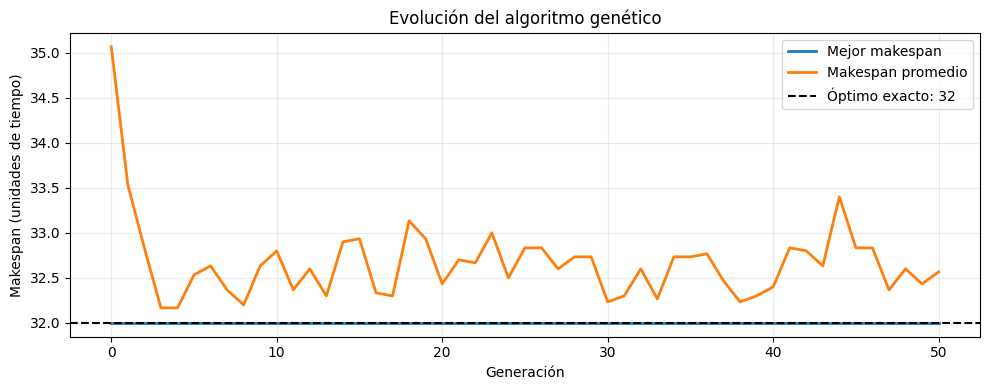

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    tabla_historial["gen"],
    tabla_historial["min"],
    label="Mejor makespan",
    linewidth=2
)

ax.plot(
    tabla_historial["gen"],
    tabla_historial["avg"],
    label="Makespan promedio",
    linewidth=2
)

ax.axhline(
    optimo_exacto,
    color="black",
    linestyle="--",
    label=f"Óptimo exacto: {optimo_exacto}"
)

ax.set(
    title="Evolución del algoritmo genético",
    xlabel="Generación",
    ylabel="Makespan (unidades de tiempo)"
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## 8. Diagrama de Gantt

Cada barra representa el procesamiento de una tarea en una máquina.
Los colores identifican las tareas y los espacios sin barras indican
periodos en los que la máquina permanece inactiva.

Se compara el orden inicial del PDF con la secuencia encontrada
por el algoritmo genético.

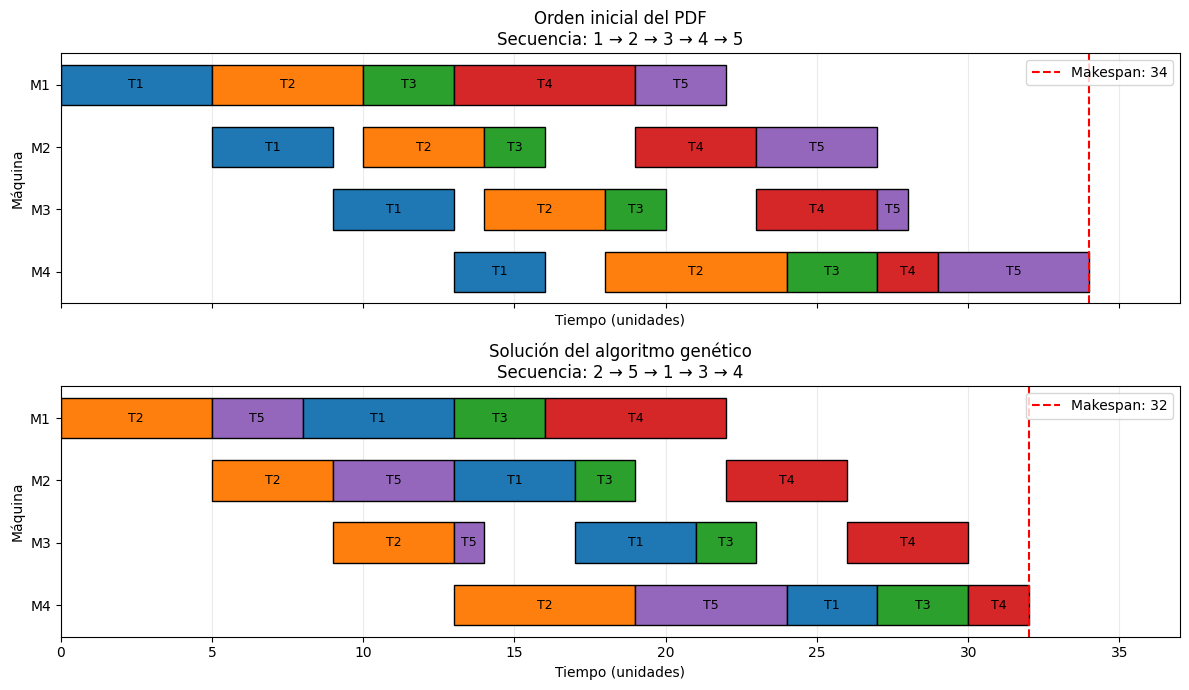

In [13]:
def dibujar_gantt(secuencia, ax, titulo):
    makespan, finalizacion = calcular_makespan(secuencia)

    colores = plt.get_cmap("tab10")

    for posicion, tarea in enumerate(secuencia):
        for maquina in range(NUM_MAQUINAS):
            duracion = int(tiempos[tarea, maquina])
            fin = int(finalizacion[posicion, maquina])
            inicio = fin - duracion

            ax.barh(
                maquina,
                duracion,
                left=inicio,
                height=0.65,
                color=colores(tarea % 10),
                edgecolor="black"
            )

            ax.text(
                inicio + duracion / 2,
                maquina,
                f"T{tarea + 1}",
                ha="center",
                va="center",
                fontsize=9
            )

    ax.set_yticks(range(NUM_MAQUINAS))
    ax.set_yticklabels([
        f"M{i + 1}" for i in range(NUM_MAQUINAS)
    ])
    ax.invert_yaxis()

    ax.axvline(
        makespan,
        color="red",
        linestyle="--",
        label=f"Makespan: {makespan}"
    )

    orden = " → ".join(str(t + 1) for t in secuencia)
    ax.set_title(f"{titulo}\nSecuencia: {orden}")
    ax.set_xlabel("Tiempo (unidades)")
    ax.set_ylabel("Máquina")
    ax.set_axisbelow(True)
    ax.grid(axis="x", alpha=0.25)
    ax.legend(loc="upper right")


fig, ejes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

dibujar_gantt(
    secuencia_prueba,
    ejes[0],
    "Orden inicial del PDF"
)

dibujar_gantt(
    mejor_individuo,
    ejes[1],
    "Solución del algoritmo genético"
)

ejes[0].set_xlim(
    0,
    max(makespan_prueba, mejor_makespan) + 3
)

fig.tight_layout()
plt.show()

## 9. Evaluación con múltiples ejecuciones

Se realizan 30 ejecuciones con diferentes semillas, manteniendo
la misma población, probabilidades y número de generaciones.

Se registra el mejor makespan de cada ejecución y se calcula
el porcentaje de ejecuciones que alcanza el óptimo exacto.
También se identifica si el óptimo ya estaba en la población inicial
o si se alcanzó durante la evolución.

In [14]:
resultados_ejecuciones = []

for semilla in range(30):
    mejor, _, registro = ejecutar_ag(semilla=semilla)

    makespan_final = int(mejor.fitness.values[0])
    mejor_inicial = int(registro[0]["min"])

    # Primera generación en la que aparece el óptimo.
    primera_gen_optima = next(
        (
            fila["gen"]
            for fila in registro
            if fila["min"] == optimo_exacto
        ),
        None
    )

    resultados_ejecuciones.append({
        "Semilla": semilla,
        "Mejor inicial": mejor_inicial,
        "Mejor final": makespan_final,
        "Alcanzó óptimo": makespan_final == optimo_exacto,
        "Primera generación óptima": primera_gen_optima
    })

tabla_ejecuciones = pd.DataFrame(resultados_ejecuciones)

display(tabla_ejecuciones)

tasa_exito = tabla_ejecuciones["Alcanzó óptimo"].mean() * 100

optimo_desde_inicio = (
    tabla_ejecuciones["Mejor inicial"] == optimo_exacto
).sum()

mejoraron = (
    tabla_ejecuciones["Mejor final"]
    < tabla_ejecuciones["Mejor inicial"]
).sum()

print(f"Tasa de éxito: {tasa_exito:.2f}%")
print(
    "Makespan final promedio:",
    round(tabla_ejecuciones["Mejor final"].mean(), 2)
)
print(
    "Desviación estándar de los resultados:",
    round(tabla_ejecuciones["Mejor final"].std(ddof=0), 2)
)
print(
    f"Ejecuciones con óptimo desde el inicio: "
    f"{optimo_desde_inicio}/30"
)
print(f"Ejecuciones que mejoraron su mínimo inicial: {mejoraron}/30")

,Semilla,Mejor inicial,Mejor final,Alcanzó óptimo,Primera generación óptima
0,0,32,32,True,0
1,1,32,32,True,0
2,2,32,32,True,0
3,3,32,32,True,0
4,4,32,32,True,0
5,5,32,32,True,0
6,6,32,32,True,0
7,7,32,32,True,0
8,8,32,32,True,0
9,9,32,32,True,0


Tasa de éxito: 100.00%
Makespan final promedio: 32.0
Desviación estándar de los resultados: 0.0
Ejecuciones con óptimo desde el inicio: 30/30
Ejecuciones que mejoraron su mínimo inicial: 0/30


## 10. Experimento con una población pequeña

Se reduce la población de 30 a 4 individuos y se mantienen las
50 generaciones, la probabilidad de cruce de 0.8 y la probabilidad
de mutación de 0.2.

Una población pequeña tiene menor probabilidad de contener el óptimo
desde el inicio. Se distingue entre las ejecuciones que comienzan
con una solución óptima y aquellas que la encuentran al evolucionar.

Este experimento permite observar el efecto del tamaño de población
en este ejemplo; no permite generalizar a todos los problemas flow-shop.

In [15]:
resultados_poblacion_pequena = []

for semilla in range(30):
    mejor, _, registro = ejecutar_ag(
        tam_poblacion=4,
        generaciones=50,
        prob_cruce=0.8,
        prob_mutacion=0.2,
        semilla=semilla
    )

    inicial = int(registro[0]["min"])
    final = int(mejor.fitness.values[0])

    primera_gen_optima = next(
        (
            fila["gen"] for fila in registro
            if fila["min"] == optimo_exacto
        ),
        None
    )

    resultados_poblacion_pequena.append({
        "Semilla": semilla,
        "Mejor inicial": inicial,
        "Mejor final": final,
        "Mejoró": final < inicial,
        "Alcanzó óptimo": final == optimo_exacto,
        "Primera generación óptima": primera_gen_optima
    })

tabla_pequena = pd.DataFrame(resultados_poblacion_pequena)
display(tabla_pequena)

inician_optimo = (
    tabla_pequena["Mejor inicial"] == optimo_exacto
)

encuentran_optimo = (
    ~inician_optimo & tabla_pequena["Alcanzó óptimo"]
)

print(
    "Óptimo desde el inicio:",
    f"{inician_optimo.sum()}/30"
)
print(
    "Encontraron el óptimo durante la evolución:",
    f"{encuentran_optimo.sum()}/30"
)
print(
    "Mejoraron su mínimo inicial:",
    f"{tabla_pequena['Mejoró'].sum()}/30"
)
print(
    "Tasa de éxito final:",
    f"{tabla_pequena['Alcanzó óptimo'].mean() * 100:.2f}%"
)

,Semilla,Mejor inicial,Mejor final,Mejoró,Alcanzó óptimo,Primera generación óptima
0,0,33,32,True,True,8
1,1,32,32,False,True,0
2,2,33,32,True,True,1
3,3,32,32,False,True,0
4,4,32,32,False,True,0
5,5,34,32,True,True,2
6,6,32,32,False,True,0
7,7,32,32,False,True,0
8,8,32,32,False,True,0
9,9,32,32,False,True,0


Óptimo desde el inicio: 21/30
Encontraron el óptimo durante la evolución: 9/30
Mejoraron su mínimo inicial: 9/30
Tasa de éxito final: 100.00%


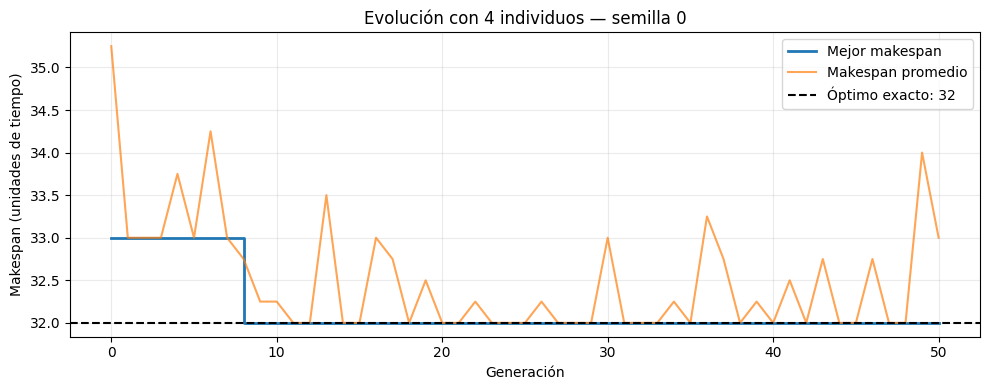

Mejor makespan inicial: 33
Mejor makespan final: 32
Secuencia final: [2, 5, 1, 4, 3]


In [16]:
# Elegir la primera ejecución que mejoró su mínimo inicial.
semilla_demo = int(
    tabla_pequena.loc[tabla_pequena["Mejoró"], "Semilla"].iloc[0]
)

mejor_demo, _, historial_demo = ejecutar_ag(
    tam_poblacion=4,
    generaciones=50,
    prob_cruce=0.8,
    prob_mutacion=0.2,
    semilla=semilla_demo
)

tabla_demo = pd.DataFrame(historial_demo)

fig, ax = plt.subplots(figsize=(10, 4))

ax.step(
    tabla_demo["gen"],
    tabla_demo["min"],
    where="post",
    linewidth=2,
    label="Mejor makespan"
)

ax.plot(
    tabla_demo["gen"],
    tabla_demo["avg"],
    alpha=0.7,
    label="Makespan promedio"
)

ax.axhline(
    optimo_exacto,
    color="black",
    linestyle="--",
    label=f"Óptimo exacto: {optimo_exacto}"
)

ax.set(
    title=f"Evolución con 4 individuos — semilla {semilla_demo}",
    xlabel="Generación",
    ylabel="Makespan (unidades de tiempo)"
)

ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

print("Mejor makespan inicial:", int(tabla_demo.iloc[0]["min"]))
print("Mejor makespan final:", int(mejor_demo.fitness.values[0]))
print("Secuencia final:", [t + 1 for t in mejor_demo])

## 11. Conclusiones

El algoritmo genético obtuvo la secuencia 2-5-1-3-4 con un makespan
de 32 unidades de tiempo. Frente al orden inicial del PDF, cuyo
makespan es 34, representa una reducción del 5.88 %.

La evaluación de las 120 permutaciones confirmó que 32 es el óptimo
global de esta instancia y que existen 25 secuencias que lo alcanzan.

Con 30 individuos, las 30 ejecuciones ya contenían una solución
óptima en su población inicial y la conservaron mediante elitismo.

Al reducir la población a 4 individuos, 21 ejecuciones comenzaron
con el óptimo y las 9 restantes lo encontraron durante la evolución.
Las 30 ejecuciones terminaron con makespan 32.

Estos resultados corresponden al ejemplo de cinco tareas y cuatro
máquinas. No garantizan que el algoritmo alcance el óptimo en
instancias mayores o con otros parámetros.